In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [4]:
df = pd.read_csv("C:\\Users\\saqli\\Downloads\\workspace\\Employee-Attrition-Project\\data\\employee_attrition.csv")

In [6]:
df.shape

(1000, 8)

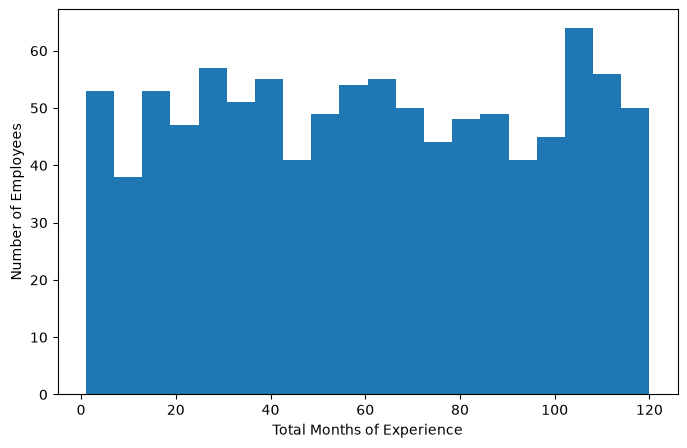

In [8]:
plt.figure(figsize=(8,5))

plt.hist(df['TotalMonthsOfExp'], bins=20)

plt.xlabel("Total Months of Experience")
plt.ylabel("Number of Employees")
plt.show()

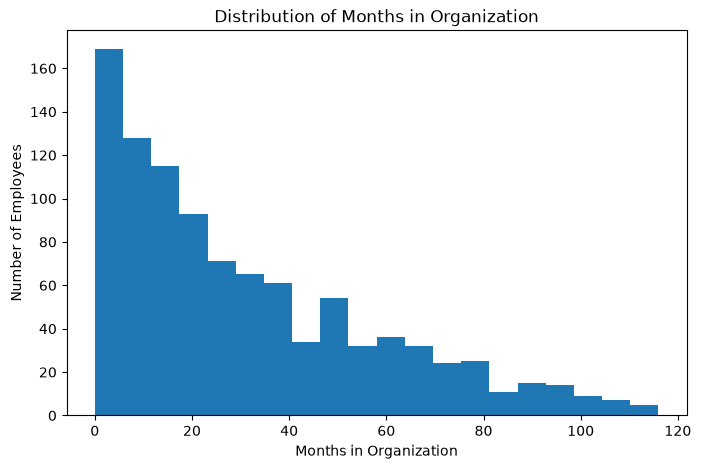

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["MonthsInOrg"], bins=20)

plt.xlabel("Months in Organization")
plt.ylabel("Number of Employees")
plt.title("Distribution of Months in Organization")

plt.show()

In [10]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_report

,Missing Count,Missing Percentage
EmployeeID,0,0.0
TotalMonthsOfExp,0,0.0
TotalOrgsWorked,0,0.0
MonthsInOrg,0,0.0
LastPayIncrementBand,0,0.0
AverageFeedback,0,0.0
LastPromotionYears,0,0.0
Attrition,0,0.0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
Q1 = df["TotalMonthsOfExp"].quantile(0.25)
Q3 = df["TotalMonthsOfExp"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 31.0
Q3: 91.25
IQR: 60.25
Lower Bound: -59.375
Upper Bound: 181.625


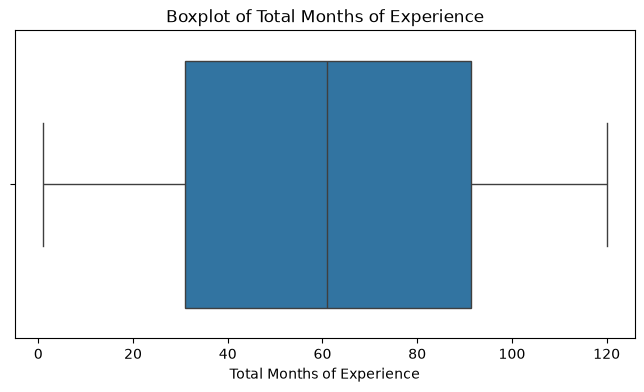

In [13]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["TotalMonthsOfExp"])

plt.title("Boxplot of Total Months of Experience")
plt.xlabel("Total Months of Experience")

plt.show()

In [14]:
correlation = df.corr(numeric_only=True)

correlation

,EmployeeID,TotalMonthsOfExp,TotalOrgsWorked,MonthsInOrg,LastPayIncrementBand,AverageFeedback,LastPromotionYears,Attrition
EmployeeID,1.000000,-0.057483,0.036784,-0.016303,-0.144755,0.055054,-0.035684,-0.036630
TotalMonthsOfExp,-0.057483,1.000000,0.053769,0.667504,-0.012453,-0.038315,0.007059,0.019702
TotalOrgsWorked,0.036784,0.053769,1.000000,0.027159,-0.003307,0.001763,-0.041774,0.008706
MonthsInOrg,-0.016303,0.667504,0.027159,1.000000,-0.017984,-0.013334,0.009309,0.012605
LastPayIncrementBand,-0.144755,-0.012453,-0.003307,-0.017984,1.000000,-0.017317,0.094561,0.108528
AverageFeedback,0.055054,-0.038315,0.001763,-0.013334,-0.017317,1.000000,-0.002145,-0.008253
LastPromotionYears,-0.035684,0.007059,-0.041774,0.009309,0.094561,-0.002145,1.000000,0.765641
Attrition,-0.036630,0.019702,0.008706,0.012605,0.108528,-0.008253,0.765641,1.000000


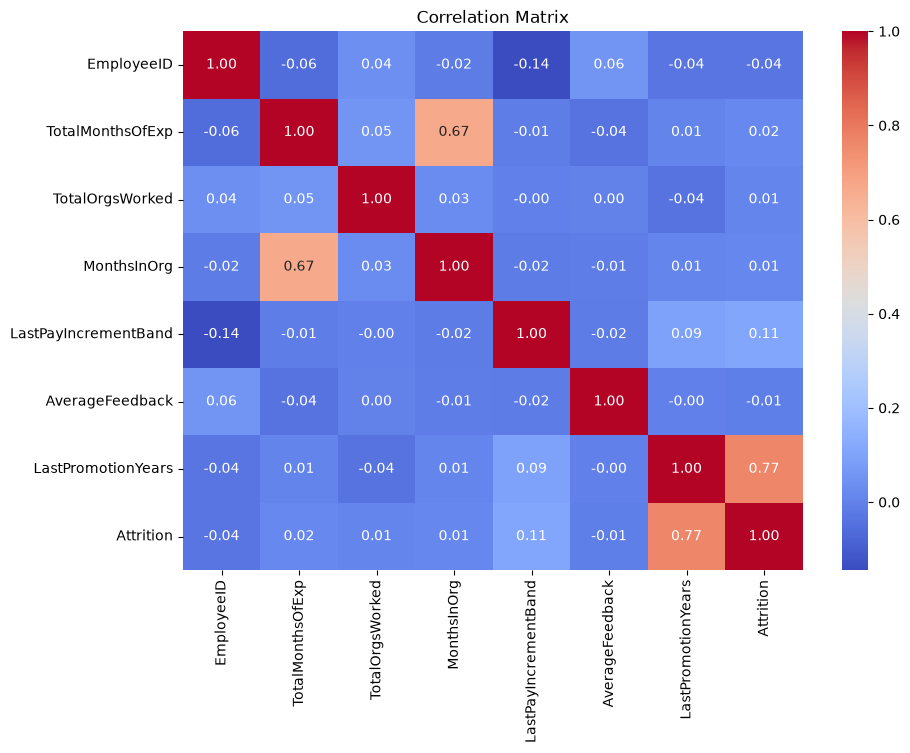

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()